In [72]:
import pandas as pd 
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import warnings
warnings.filterwarnings("ignore")

data = pd.read_csv('policja_informacja_dzienna.csv')

subject = "ranni"

data['data'] = pd.to_datetime(data['data'])

# data = data[data['data'] >= '2018-01-01']
data.set_index('data', inplace=True)

data = data.asfreq('D')

# print(data.head())
# print("Liczba kolumn", data.index.__len__)

suma_brakow = data[subject].isna().sum()
print(f'Suma braków w kolumnie interwencje: {suma_brakow}')

data[subject] = data[subject].interpolate(method='linear')
suma_brakow_po_interpolacji = data[subject].isna().sum()
print(f'Suma braków w kolumnie {subject} po interpolacji: {suma_brakow_po_interpolacji}')



Suma braków w kolumnie interwencje: 39
Suma braków w kolumnie ranni po interpolacji: 0


Suma kwadratów błędów: 2588206.762474074
smoothing_level 0.1242
smoothing_trend 0.0
smoothing_seasonal 0.0


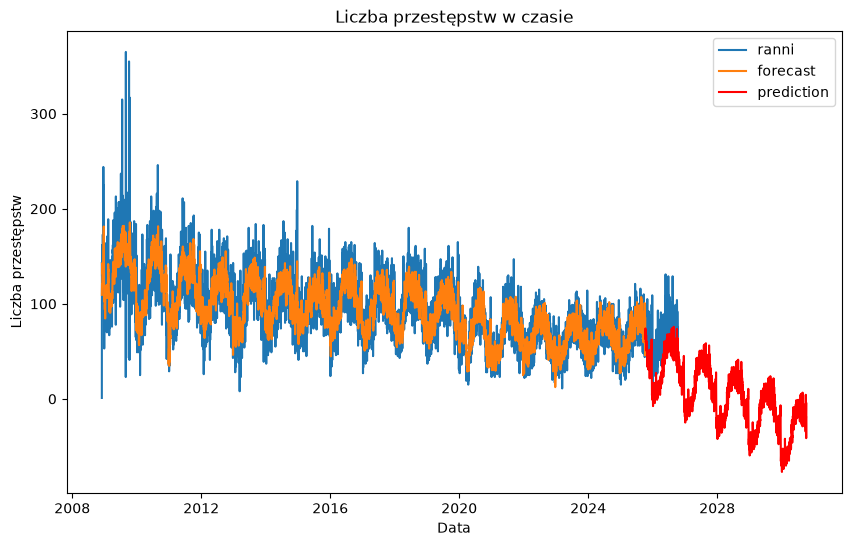

In [79]:
# data[subject] = data[subject].interpolate(method='linear')

y = data[subject]
h=365

train = y.iloc[:-h]
test = y.iloc[-h:]

model = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=365).fit(
    # smoothing_seasonal=0.02, smoothing_trend=0.02, smoothing_level=0.02
)
data['forecast'] = model.fittedvalues

print(f"Suma kwadratów błędów: {model.sse}")


prediction = model.forecast(h*5)

for nazwa in ['smoothing_level', 'smoothing_trend', 'smoothing_seasonal']:
    print(nazwa, round(model.params[nazwa], 4))


plt.figure(figsize=(10, 6))
plt.plot(data.index, data[subject], label=subject)
plt.plot(data.index, data['forecast'], label='forecast')
# plt.plot(data.index[-h:], prediction, label='prediction', color='red')
plt.plot(prediction.index, prediction, label='prediction', color='red')
plt.xlabel('Data')
plt.ylabel('Liczba przestępstw')
plt.title('Liczba przestępstw w czasie')
plt.legend()
plt.show()

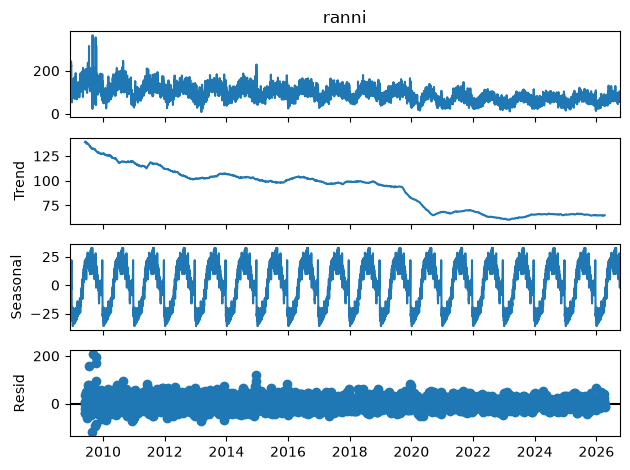

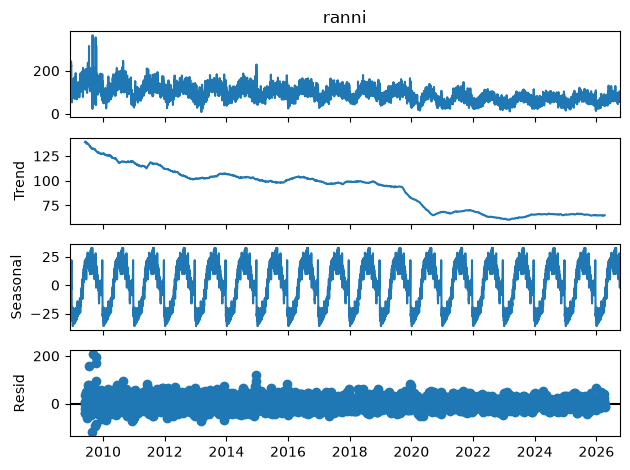

In [69]:
# Seasonal decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(y, model='additive', period=365)

decomposition.plot()

In [ ]:
import itertools
import warnings

# Grid search parametrów α, β, γ.
# Parametry wybieramy na zbiorze walidacyjnym (ostatnie h dni treningu),
# a zbiór testowy zostaje nietknięty do końcowej oceny.
train_gs = train.iloc[:-h]
valid = train.iloc[-h:]

alphas = [0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.3]  # smoothing_level
betas = [0.0, 0.01]                                  # smoothing_trend
gammas = [0.0, 0.1, 0.2, 0.3]                        # smoothing_seasonal

wyniki = []
for alpha, beta, gamma in itertools.product(alphas, betas, gammas):
    if beta > alpha:  # ten sam warunek β <= α, który stosuje automatyczny .fit()
        continue
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')  # ConvergenceWarning przy seasonal_periods=365
        m = ExponentialSmoothing(train_gs, trend='add', seasonal='add', seasonal_periods=365).fit(
            smoothing_level=alpha, smoothing_trend=beta, smoothing_seasonal=gamma
        )
    mae = (valid - m.forecast(h)).abs().mean()
    wyniki.append({'alpha': alpha, 'beta': beta, 'gamma': gamma, 'mae_valid': mae})

wyniki = pd.DataFrame(wyniki).sort_values('mae_valid')
print(wyniki.head(10).to_string(index=False))

najlepsze = wyniki.iloc[0]
print(f"\nNajlepsze parametry: alpha={najlepsze['alpha']}, beta={najlepsze['beta']}, gamma={najlepsze['gamma']}")

# Końcowa ocena na teście: model z najlepszymi parametrami dopasowany na całym treningu
# kontra model z automatycznym .fit() z poprzedniej komórki.
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    model_gs = ExponentialSmoothing(train, trend='multiplicative', seasonal='multiplicative', seasonal_periods=365).fit(
        smoothing_level=najlepsze['alpha'],
        smoothing_trend=najlepsze['beta'],
        smoothing_seasonal=najlepsze['gamma'],
    )
prognoza_gs = model_gs.forecast(h*10)
prognoza_auto = model.forecast(h*10)

print(f"\nMAE na teście, grid search:      {(test - prognoza_gs).abs().mean():.2f}")
print(f"MAE na teście, automatyczny fit: {(test - prognoza_auto).abs().mean():.2f}")

plt.figure(figsize=(12, 6))
plt.plot(test.index, test, label='test', color='gray')
plt.plot(prognoza_auto.index, prognoza_auto, label='automatyczny .fit()')
plt.plot(prognoza_gs.index, prognoza_gs, label='grid search', color='red')
plt.xlabel('Data')
plt.ylabel(subject)
plt.legend()
plt.show()